# 👁️ Eye State — MobileNetV2 + Fine-tuning (Synapse)

**الهدف:** نفس مهمة الـ baseline (مغلقة 0 / مفتوحة 1)، بس بدل ما نبني CNN من الصفر،
بنستخدم **MobileNetV2 متدرب مسبقاً على ImageNet** (1.4 مليون صورة) ونعمله **Fine-tuning**.

**ليش؟** النموذج الجاهز تعلّم مسبقاً يشوف حواف وأشكال وملمس — بنستفيد من هالمعرفة بدل ما نبدأ من صفر ← غالباً دقة أعلى وتعميم أفضل على أشخاص جدد.

**ليش MobileNetV2 بالذات؟** خفيف وسريع (مصمم للموبايل) ← مناسب للكاميرا والـ real-time.

| المرحلة | شو بنعمل | الـ LR |
|---|---|---|
| **1) Feature extraction** | نجمّد MobileNetV2 كامل وندرب الـ head الجديد بس | `1e-3` |
| **2) Fine-tuning** | نفك تجميد آخر الطبقات وندربهم مع الـ head | `1e-5` (صغير جداً) |

## 1) تجهيز البيئة
نفس الـ baseline: نفس الـ loader تبع منار ونفس الـ splits ← **المقارنة عادلة** (أي فرق بالنتائج سببه النموذج مش الداتا).

In [1]:
import os, sys, json, glob
if not os.path.exists("Synapse"):
    !git clone -q https://github.com/ManarAbu-Irsheid/Synapse.git
sys.path.insert(0, "Synapse/data_pipeline")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from dataset import make_dataset

tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2) الإعدادات
- `BACKBONE_SIZE = 96`: MobileNetV2 عنده أوزان ImageNet جاهزة لأحجام محددة (96، 128، 160، 192، 224). أصغرها 96 ← سريع ومناسب لصورة عين صغيرة.
- `FINE_TUNE_AT = 100`: من أصل ~154 طبقة، بنفك تجميد الطبقات من 100 وطالع (آخر ~54 طبقة).
  **ليش آخر الطبقات بس؟** الطبقات الأولى بتتعلم أشياء عامة (حواف، ألوان) مفيدة لأي صورة — ما بدنا نخربها. الطبقات الأخيرة بتتعلم أشياء خاصة بـ ImageNet (قطط، سيارات) — هاي يلي لازم تتأقلم على العيون.

In [2]:
SPLITS        = "Synapse/data_pipeline/splits"
OUT           = "/kaggle/working/eye_mobilenetv2"
IMG_SIZE      = 64        # حجم الصورة من الـ loader (نفس الـ real-time)
BACKBONE_SIZE = 96        # الحجم يلي بيدخل MobileNetV2
BATCH         = 64
LR_HEAD, EPOCHS_HEAD = 1e-3, 10
LR_FT,   EPOCHS_FT   = 1e-5, 15
FINE_TUNE_AT  = 100
CLASS_NAMES   = ["closed", "open"]
os.makedirs(OUT, exist_ok=True)

## 3) تحميل الداتا (نفس الـ baseline بالضبط)

In [3]:
dfs = {s: pd.read_csv(f"{SPLITS}/mrl_{s}.csv") for s in ["train", "val", "test"]}
for s, d in dfs.items():
    print(f"{s:5s}: {len(d):6d} images | subjects={d.subject.nunique()}")
missing = [p for p in dfs["train"].path.head(20) if not os.path.exists(p)]
assert not missing, f"المسارات مش موجودة! ضيفي MRL Eye Dataset كـ Input. مثال: {missing[0]}"

# ⚠️ إصلاح: ملف mrl_train.csv مرتّب (كل الـ closed أول، بعدين كل الـ open)، والـ shuffle buffer
# بالـ loader (10,000) أصغر من الداتا (55,330) ← الـ batches بتطلع من فئة وحدة تقريباً
# وهاد بيخرب الـ BatchNorm. الحل: نخلط الملف كامل مرة وحدة قبل ما نعطيه للـ loader.
os.makedirs("/kaggle/working/splits_shuffled", exist_ok=True)
TRAIN_CSV = "/kaggle/working/splits_shuffled/mrl_train.csv"
dfs["train"].sample(frac=1, random_state=42).to_csv(TRAIN_CSV, index=False)
lab = pd.read_csv(TRAIN_CSV).label.values
n = min(10, len(lab) // BATCH)
first = lab[:n * BATCH].reshape(n, BATCH).mean(1)
print(f"نسبة open بأول {n} batches بعد الخلط:", first.round(2))   # لازم تكون قريبة من 0.5

train_ds = make_dataset(TRAIN_CSV, training=True,  batch_size=BATCH, size=IMG_SIZE)
val_ds   = make_dataset(f"{SPLITS}/mrl_val.csv",   training=False, batch_size=BATCH, size=IMG_SIZE)
test_ds  = make_dataset(f"{SPLITS}/mrl_test.csv",  training=False, batch_size=BATCH, size=IMG_SIZE)
print("✅ الداتا جاهزة")

train:  55330 images | subjects=25
val  :  23502 images | subjects=6
test :   6066 images | subjects=6
نسبة open بأول 10 batches بعد الخلط: [0.5  0.56 0.41 0.66 0.56 0.58 0.45 0.48 0.52 0.47]
✅ الداتا جاهزة


## 4) بناء النموذج
**مشكلة توافق:** صورنا **رمادية (قناة وحدة)** وقيمها **0 → 1**، بس MobileNetV2 بيتوقع **RGB (3 قنوات)** وقيم **‎-1 → 1**.

**الحل — 3 طبقات تحضير جوّا النموذج نفسه:**
| الطبقة | شو بتعمل | ليش جوّا النموذج؟ |
|---|---|---|
| `Resizing(96, 96)` | تكبير 64 ← 96 | |
| `Concatenate([x, x, x])` | تكرار القناة الرمادية 3 مرات | |
| `Rescaling(2, offset=-1)` | تحويل 0→1 إلى ‎-1→1 | |

> **ليش جوّا النموذج؟** عشان النموذج يضل ياخذ **نفس مدخل الـ baseline** (64×64×1 من `preprocess_eye`) ← باقي الفريق ما بيغيّر ولا سطر بالـ real-time.

**الـ head الجديد:** `GlobalAveragePooling → Dropout(0.3) → Dense(1, sigmoid)`

**ملاحظة مهمة:** بنستدعي MobileNetV2 بـ `training=False` ← طبقات الـ BatchNorm بتضل بإحصائيات ImageNet حتى وقت الـ Fine-tuning. لو ما عملنا هيك، الدفعات الصغيرة بتخرب الإحصائيات والدقة بتنهار.

In [4]:
def build_eye_mobilenet():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 1), name="eye_gray")
    x = layers.Resizing(BACKBONE_SIZE, BACKBONE_SIZE)(inp)
    x = layers.Concatenate()([x, x, x])                  # gray -> 3 channels
    x = layers.Rescaling(2.0, offset=-1.0)(x)            # [0,1] -> [-1,1]
    base = keras.applications.MobileNetV2(
        input_shape=(BACKBONE_SIZE, BACKBONE_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False                               # المرحلة 1: تجميد كامل
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid", name="p_open")(x)
    return keras.Model(inp, out, name="eye_mobilenetv2"), base

model, base = build_eye_mobilenet()
print("طبقات MobileNetV2:", len(base.layers))
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
طبقات MobileNetV2: 154


Model: "eye_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ eye_gray            │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing (Resizing) │ (None, 96, 96, 1) │          0 │ eye_gray[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 96, 96, 3) │          0 │ resizing[0][0],   │
│ (Concatenate)       │                   │            │ resizing[0][0],   │
│                     │                   │            │ resizing[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 96, 96, 3) │          0 │ concatenate[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_96 │ (None, 3, 3,      │  2,257,984 │ rescaling[0][0]   │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_open (Dense)      │ (None, 1)         │      1,281 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5) المرحلة 1 — تدريب الـ head بس (Feature Extraction)
- MobileNetV2 **مجمّد** ← بنستخدمه كـ "مستخرج features" جاهز.
- **ليش أول؟** الـ head الجديد أوزانه عشوائية ← لو فكينا التجميد من البداية، الأخطاء الكبيرة بتنتقل للنموذج الجاهز وبتخرب يلي تعلمه.

In [5]:
METRICS = ["accuracy", keras.metrics.Precision(name="precision"),
           keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")]

def callbacks(stage, patience):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(f"{OUT}/best_{stage}.keras", monitor="val_loss", save_best_only=True),
        keras.callbacks.CSVLogger(f"{OUT}/history_{stage}.csv"),
    ]

model.compile(optimizer=keras.optimizers.Adam(LR_HEAD), loss="binary_crossentropy", metrics=METRICS)
print("Trainable params:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks("head", 3))

Trainable params: 1281
Epoch 1/10
865/865 ━━━━━━━━━━━━━━━━━━━━ 1646s 2s/step - accuracy: 0.9262 - auc: 0.9772 - loss: 0.1951 - precision: 0.9440 - recall: 0.9115 - val_accuracy: 0.9399 - val_auc: 0.9857 - val_loss: 0.1521 - val_precision: 0.9344 - val_recall: 0.9432 - learning_rate: 0.0010
Epoch 2/10
865/865 ━━━━━━━━━━━━━━━━━━━━ 28s 32ms/step - accuracy: 0.9490 - auc: 0.9875 - loss: 0.1399 - precision: 0.9602 - recall: 0.9404 - val_accuracy: 0.9368 - val_auc: 0.9854 - val_loss: 0.1563 - val_precision: 0.9207 - val_recall: 0.9526 - learning_rate: 0.0010
Epoch 3/10
865/865 ━━━━━━━━━━━━━━━━━━━━ 28s 33ms/step - accuracy: 0.9528 - auc: 0.9887 - loss: 0.1313 - precision: 0.9627 - recall: 0.9453 - val_accuracy: 0.9394 - val_auc: 0.9857 - val_loss: 0.1509 - val_precision: 0.9295 - val_recall: 0.9478 - learning_rate: 0.0010
Epoch 4/10
865/865 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.9553 - auc: 0.9892 - loss: 0.1277 - precision: 0.9644 - recall: 0.9485 - val_accuracy: 0.9398 - val_auc: 

## 6) المرحلة 2 — Fine-tuning
- بنفك تجميد الطبقات من `FINE_TUNE_AT` وطالع، **ما عدا BatchNorm** (بتضل مجمّدة).
- **LR أصغر 100 مرة** (`1e-5`) ← تعديلات صغيرة جداً، بنحسّن المعرفة الموجودة بدل ما نمسحها.
- **لازم `compile` من جديد** بعد تغيير `trainable` — وإلا التغيير ما بيتطبق.

In [6]:
base.trainable = True
for layer in base.layers[:FINE_TUNE_AT]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(LR_FT), loss="binary_crossentropy", metrics=METRICS)
print("Trainable params:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))
h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, callbacks=callbacks("finetune", 4))

Trainable params: 1840897
Epoch 1/15


E0000 00:00:1795176665.869330      78 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795176666.026183      78 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


862/865 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9633 - auc: 0.9892 - loss: 0.1036 - precision: 0.9402 - recall: 0.9604

E0000 00:00:1795176696.309534      80 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795176696.467957      80 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


865/865 ━━━━━━━━━━━━━━━━━━━━ 59s 50ms/step - accuracy: 0.9681 - auc: 0.9918 - loss: 0.0894 - precision: 0.9546 - recall: 0.9635 - val_accuracy: 0.9415 - val_auc: 0.9935 - val_loss: 0.1308 - val_precision: 0.9033 - val_recall: 0.9858 - learning_rate: 1.0000e-05
Epoch 2/15
865/865 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.9780 - auc: 0.9971 - loss: 0.0606 - precision: 0.9797 - recall: 0.9778 - val_accuracy: 0.9645 - val_auc: 0.9940 - val_loss: 0.0903 - val_precision: 0.9627 - val_recall: 0.9647 - learning_rate: 1.0000e-05
Epoch 3/15
865/865 ━━━━━━━━━━━━━━━━━━━━ 28s 33ms/step - accuracy: 0.9821 - auc: 0.9981 - loss: 0.0497 - precision: 0.9830 - recall: 0.9824 - val_accuracy: 0.9554 - val_auc: 0.9924 - val_loss: 0.1071 - val_precision: 0.9509 - val_recall: 0.9581 - learning_rate: 1.0000e-05
Epoch 4/15
864/865 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9847 - auc: 0.9986 - loss: 0.0409 - precision: 0.9846 - recall: 0.9859
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.99

## 7) منحنيات التدريب (المرحلتين)
الخط المتقطع = لحظة بداية الـ Fine-tuning. المتوقع: قفزة تحسن صغيرة بعده.

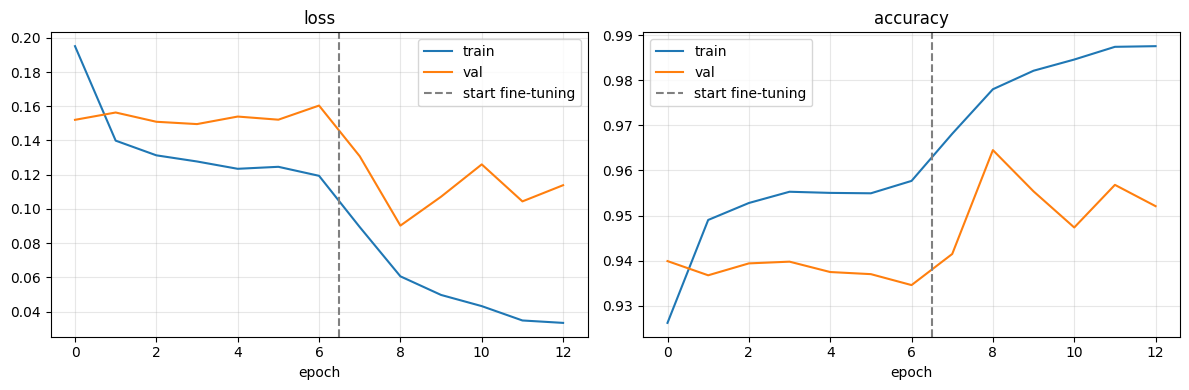

In [7]:
h = pd.concat([pd.DataFrame(h1.history), pd.DataFrame(h2.history)], ignore_index=True)
split = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(h[m], label="train"); ax[i].plot(h[f"val_{m}"], label="val")
    ax[i].axvline(split - 0.5, ls="--", c="gray", label="start fine-tuning")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend(); ax[i].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.show()

## 8) التقييم على الـ Test Set
نفس طريقة الـ baseline بالضبط. **أهم رقم: Recall لفئة closed.**

              precision    recall  f1-score   support

      closed     0.9783    0.9370    0.9572      3222
        open     0.9319    0.9764    0.9536      2844

    accuracy                         0.9555      6066
   macro avg     0.9551    0.9567    0.9554      6066
weighted avg     0.9565    0.9555    0.9555      6066



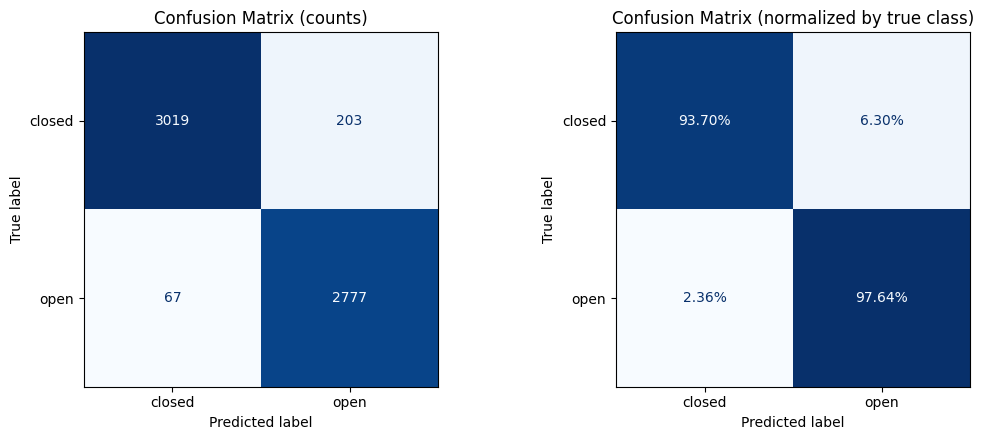

In [8]:
y_true = dfs["test"].label.values
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true"),
                       display_labels=CLASS_NAMES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2%")
ax[1].set_title("Confusion Matrix (normalized by true class)")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=120); plt.show()

## 9) حفظ النموذج والنتائج

In [9]:
model.save(f"{OUT}/eye_mobilenetv2.keras")
model.save_weights(f"{OUT}/eye_mobilenetv2.weights.h5")
h.to_csv(f"{OUT}/history.csv", index=False)

test_eval = model.evaluate(test_ds, verbose=0, return_dict=True)
metrics = {
    "model": "eye_mobilenetv2_finetuned",
    "params": int(model.count_params()),
    "epochs_head": split, "epochs_finetune": len(h) - split,
    "best_val_loss": float(h.val_loss.min()),
    "test_accuracy": report["accuracy"],
    "test_auc": float(test_eval["auc"]),
    "closed": {k: report["closed"][k] for k in ["precision", "recall", "f1-score", "support"]},
    "open":   {k: report["open"][k]   for k in ["precision", "recall", "f1-score", "support"]},
    "confusion_matrix": cm.tolist(),
    "hyperparameters": {"img_size": IMG_SIZE, "backbone_size": BACKBONE_SIZE, "batch": BATCH,
                        "lr_head": LR_HEAD, "lr_finetune": LR_FT, "fine_tune_at": FINE_TUNE_AT},
}
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("\nFiles:", sorted(os.listdir(OUT)))

{
  "model": "eye_mobilenetv2_finetuned",
  "params": 2259265,
  "epochs_head": 7,
  "epochs_finetune": 6,
  "best_val_loss": 0.09025023877620697,
  "test_accuracy": 0.9554896142433235,
  "test_auc": 0.9908815026283264,
  "closed": {
    "precision": 0.9782890473104342,
    "recall": 0.9369956548727498,
    "f1-score": 0.9571972098922004,
    "support": 3222.0
  },
  "open": {
    "precision": 0.9318791946308724,
    "recall": 0.9764416315049227,
    "f1-score": 0.9536401098901099,
    "support": 2844.0
  },
  "confusion_matrix": [
    [
      3019,
      203
    ],
    [
      67,
      2777
    ]
  ],
  "hyperparameters": {
    "img_size": 64,
    "backbone_size": 96,
    "batch": 64,
    "lr_head": 0.001,
    "lr_finetune": 1e-05,
    "fine_tune_at": 100
  }
}

Files: ['best_finetune.keras', 'best_head.keras', 'confusion_matrix.png', 'eye_mobilenetv2.keras', 'eye_mobilenetv2.weights.h5', 'history.csv', 'history_finetune.csv', 'history_head.csv', 'metrics.json', 'training_curves.png'

## 10) مقارنة مع الـ Baseline
**اختياري:** لو ضفتي output نوتبوك `eye-cnn-training` كـ Input (**Add Input ← Your Work**)، الخلية بتلاقي `metrics.json` تبع الـ baseline لحالها وبتعمل جدول مقارنة.

In [10]:
found = glob.glob("/kaggle/input/**/eye_cnn_baseline/metrics.json", recursive=True)
if not found:
    print("ما لقيت metrics الـ baseline — ضيفي output نوتبوك eye-cnn-training كـ Input لو بدك المقارنة.")
else:
    base_m = json.load(open(found[0]))
    rows = []
    for m in [base_m, metrics]:
        rows.append({"model": m["model"], "params": m["params"],
                     "test_accuracy": m["test_accuracy"], "test_auc": m["test_auc"],
                     "closed_recall": m["closed"]["recall"], "closed_precision": m["closed"]["precision"],
                     "open_recall": m["open"]["recall"]})
    cmp = pd.DataFrame(rows).set_index("model")
    cmp.to_csv(f"{OUT}/comparison_vs_baseline.csv")
    display(cmp.style.format("{:.4f}", subset=cmp.columns[1:]))

,params,test_accuracy,test_auc,closed_recall,closed_precision,open_recall
model,,,,,,
eye_cnn_baseline,304417,0.9746,0.9967,0.9609,0.9910,0.9902
eye_mobilenetv2_finetuned,2259265,0.9555,0.9909,0.9370,0.9783,0.9764


## 11) الاستخدام بالـ real-time
**نفس كود الـ baseline بالضبط** — بس غيّري اسم الملف:
```python
model = keras.models.load_model("eye_mobilenetv2.keras")
p_open = model.predict(preprocess_eye(eye_roi_bgr)[None], verbose=0)[0, 0]
```
**الخطوة الجاية:** Hyperparameter tuning لأفضل نموذج.